In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load data
nut_df = pd.read_csv('NRC_BME690/bme_690_all_nuts.csv')
spice_df = pd.read_csv('NRC_BME690/bme_690_all_spices.csv')
herb_df = pd.read_csv('NRC_BME690/bme_690_all_herbs.csv')
sensor_df = pd.concat([nut_df, spice_df, herb_df], ignore_index=True)

sensor_df['log_resistance'] = np.log10(sensor_df['resistance_gassensor'] + 1)  # Add 1 to avoid log(0)
sensor_df['label_merged'] = sensor_df['label'].str.rstrip('0123456789') # merge labels like peanuts2 -> peanuts
sensor_df.head()
    

,sensor_index,sensor_id,timestamp_since_poweron,real_time_clock,temperature,pressure,relative_humidity,resistance_gassensor,heater_profile_step_index,scanning_enabled,scanning_cycle_index,label_tag,error_code,label,class,source_file,log_resistance,label_merged
0,1,880502628,664224,0,36.709148,1021.732239,27.176279,262093.671875,6,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,5.418458,Pecans
1,0,880490094,664244,0,36.242775,1021.761719,27.640745,90459.367188,7,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,4.956458,Pecans
2,3,880492645,664370,0,36.640404,1021.617310,28.554050,96731.531250,8,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,4.985573,Pecans
3,6,880494957,664802,0,35.828842,1021.619568,28.506971,137044.968750,8,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,5.136866,Pecans
4,0,880490094,664944,0,36.335953,1021.758911,27.802603,106711.132812,8,1,1,0,0,Pecans,nuts,bme_690_data_11.csv,5.028214,Pecans


In [2]:
# Configuration: Choose your sensor K (0, 1, 2, or 3)
K = 1
PAIR_K = K + 4
# FEATURE_LABEL is what is used for classification later on.
# FEATURE_LABEL = 'resistance_gassensor'
# FEATURE_LABEL = 'log_resistance' 
FEATURE_LABEL = 'resistance_compensated'
# FEATURE_LABEL = 'diff_log_resistance' 
# FEATURE_LABEL = 'diff_resistance_compensated'
LABEL = 'Chestnuts'

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

def normalize_by_group(df):
    def calculate_log_vapor_pressure(temp_c, rh_percent):
        # Constants for Magnus-Tetens
        A = 17.67
        B = 243.5
        C = 6.112 # hPa

        # Saturation Vapor Pressure (Maximum water the air can hold at this T)
        p_s = C * np.exp((A * temp_c) / (temp_c + B))

        # Actual Vapor Pressure (The partial pressure of water vapor)
        p_a = p_s * (rh_percent / 100.0)

        return np.log10(p_a) # Returns log pressure in hPa

    def get_residuals(group):
        # We need at least 2 points to fit a line; otherwise, return 0 (centered)
        if len(group) < 2:
            return pd.Series(0, index=group.index)
        
        X = calculate_log_vapor_pressure(group['temperature'], group['relative_humidity']).to_frame(name="log_vapor_pressure")
        y = group['log_resistance']
        
        model = LinearRegression()
        model.fit(X, y)
        
        # Residual = Actual - Predicted
        return y - model.predict(X)
        # Simpler version: subtract mean, ignore vapor pressure 
        # return y - np.mean(y)

    # Group by sensor and step to isolate specific heater behaviors
    # This automatically handles the 4 different profiles across the 8 sensors
    # Since response to envionmental conditions (temperature, humidity) depends on sensor temperature,
    # remove the baseline response for each step to help generalize across sensors
    return df.groupby(['sensor_index', 'heater_profile_step_index'], 
                                     group_keys=False).apply(get_residuals, include_groups=False)
    # Simpler: Group by sensor only, average across all heater steps
    # return df.groupby(['sensor_index'], 
    #                                 group_keys=False).apply(get_residuals, include_groups=False)

def prepare_sensor_features(df):
    # Sort by trial, sensor, and time to ensure sequential cycle identification
    df = df.sort_values(['source_file', 'sensor_index', 'timestamp_since_poweron', 'heater_profile_step_index'])
    
    # Identify the start of a new cycle (step index 0)
    df['cycle_start'] = (df['heater_profile_step_index'] == 0).astype(int)
    df['cycle_id'] = df.groupby('sensor_index')['cycle_start'].cumsum()

    # Capture the timestamp of the first step in each cycle
    # We create a mapping of (sensor, cycle) -> start_timestamp
    cycle_times = df[df['heater_profile_step_index'] == 0].groupby(['sensor_index', 'cycle_id'])['timestamp_since_poweron'].first().reset_index()
    cycle_times.rename(columns={'timestamp_since_poweron': 'cycle_start_timestamp'}, inplace=True)

    # Define the features to pivot
    value_vars = ['resistance_gassensor', 'resistance_compensated', 'log_resistance', 'temperature', 'relative_humidity']
    
    # Pivot the data: Features become columns per step index
    feature_pivot = df.pivot_table(
        index=['sensor_index', 'cycle_id', 'label_merged', 'class'],
        columns='heater_profile_step_index',
        values=value_vars
    )

    # Flatten the multi-index columns
    feature_pivot.columns = [f"{val}_{int(step)}" for val, step in feature_pivot.columns]
    feature_pivot = feature_pivot.reset_index()

    # 6. Merge the start timestamp back into the feature matrix
    feature_pivot = pd.merge(
        feature_pivot, 
        cycle_times, 
        on=['sensor_index', 'cycle_id'], 
        how='left'
    )

    # 7. Drop incomplete cycles (rows where a step was missed and resulted in NaN)
    feature_pivot = feature_pivot.dropna()

    return feature_pivot


sensor_df['resistance_compensated'] = normalize_by_group(sensor_df)
feature_matrix = prepare_sensor_features(sensor_df)
feature_matrix.head()


,sensor_index,cycle_id,label_merged,class,log_resistance_0,log_resistance_1,log_resistance_2,log_resistance_3,log_resistance_4,log_resistance_5,...,temperature_1,temperature_2,temperature_3,temperature_4,temperature_5,temperature_6,temperature_7,temperature_8,temperature_9,cycle_start_timestamp
1,0,1,Pecans,nuts,5.083447,7.104251,7.021992,6.909822,5.722835,5.678166,...,36.253422,35.795494,35.726269,36.029785,36.106995,36.152252,36.248096,36.341278,36.391861,666500.0
2,0,2,Pecans,nuts,5.107865,7.148094,7.061368,6.947248,5.754185,5.705703,...,36.226799,35.838093,35.739582,36.051083,36.138943,36.189526,36.301342,36.391861,36.426472,677307.0
3,0,3,Pecans,nuts,5.120106,7.172830,7.090813,6.961931,5.767387,5.720489,...,36.269398,35.878029,35.750229,36.045761,36.138943,36.178879,36.282707,36.378551,36.410496,688273.0
4,0,4,Pecans,nuts,5.127210,7.181499,7.096486,6.964488,5.773763,5.725532,...,36.256084,35.872704,35.758217,36.051083,36.144268,36.173553,36.280045,36.373226,36.415821,699211.0
5,0,5,Pecans,nuts,5.118097,7.165202,7.076749,6.952563,5.766643,5.720823,...,36.240112,35.867378,35.790169,36.093681,36.184200,36.237450,36.362576,36.450432,36.511662,710171.0


In [4]:
def row_wise_delta(df, feature_prefix='log_resistance'):
    # Identify the columns that make up the feature vector
    # (Excluding metadata like sensor_index, cycle_id, and label)
    feature_cols = [c for c in df.columns if feature_prefix in c]
    
    # Extract the data as a matrix
    X = df[feature_cols].values
    
    # # Calculate first difference for each row, "first difference instance normalization"
    # row_diff = np.diff(X, axis=1)
    # # Prepend a column of zeros to maintain the same shape (or you could choose to drop the first column)
    # row_diff = np.hstack([np.zeros((row_diff.shape[0], 1)), row_diff])

    # take delta relative to first column, "first sample instance normalization"
    row_diff = X - X[:, 0, None]
    
    # Add new difference columns to the existing dataframe
    for col_idx, col_name in enumerate(feature_cols):
        diff_col_name = f"diff_{col_name}"
        
        df[diff_col_name] = row_diff[:, col_idx]
    
    return df

# Usage
feature_matrix = row_wise_delta(feature_matrix, feature_prefix='resistance_compensated')

,sensor_index,sensor_id,timestamp_since_poweron,real_time_clock,temperature,pressure,relative_humidity,resistance_gassensor,heater_profile_step_index,scanning_enabled,scanning_cycle_index,label_tag,error_code,label,class,source_file,log_resistance,label_merged,resistance_compensated
57890,1,880502628,1959137,0,38.344452,1015.221863,21.694527,3.361786e+05,6,1,1,2,0,Chestnuts,nuts,bme_690_data_17.csv,5.526571,Chestnuts,0.317077
57901,1,880502628,1962497,0,38.029587,1015.245544,22.063271,9.841422e+05,7,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,5.993058,Chestnuts,0.438468
57920,1,880502628,1965857,0,37.667084,1015.288513,30.264982,3.393538e+06,8,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,6.530653,Chestnuts,0.510378
57932,1,880502628,1969227,0,37.915810,1015.364929,33.076923,5.929358e+05,9,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,5.773008,Chestnuts,0.396059
57948,1,880502628,1972637,0,38.095737,1015.392151,33.977844,1.184911e+05,0,1,1,1,0,Chestnuts,nuts,bme_690_data_17.csv,5.073689,Chestnuts,0.196461


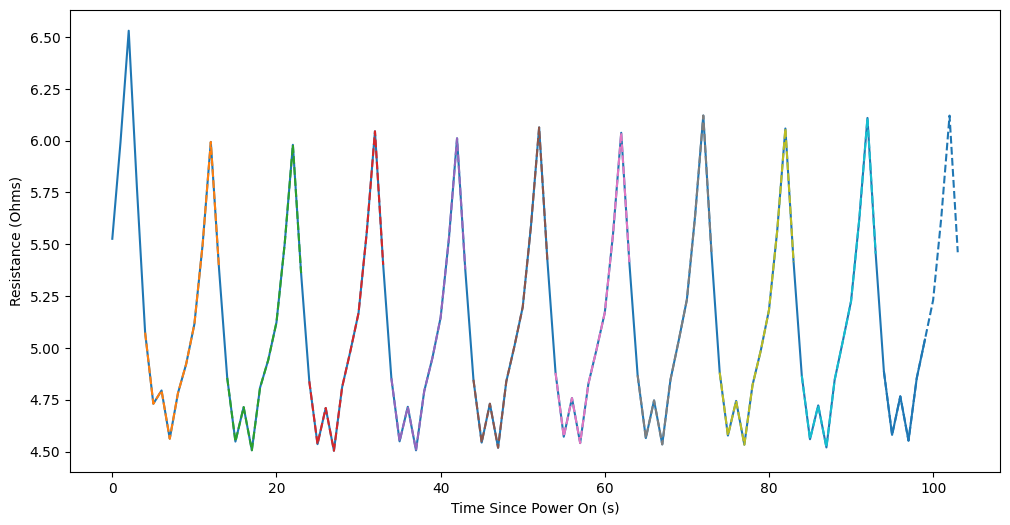

In [5]:
# Sanity check: compare the pivoted features to the original time series
target_feature = 'log_resistance'
plt.figure(figsize=(12, 6))
subset = sensor_df[(sensor_df['sensor_index'] == K) & (sensor_df['label_merged'] == LABEL)]
# Extract the first 100 data points
subset = subset.head(100)
plt.plot(np.arange(len(subset)),subset[target_feature], label=LABEL)

# overlay the pivoted data from the feature matrix for the same LABEL and sensor K
feature_subset = feature_matrix[(feature_matrix['sensor_index'] == K) & (feature_matrix['label_merged'] == LABEL)]
feat_cols = [col for col in feature_matrix.columns if col.startswith(target_feature)]
dat = feature_subset[feat_cols].values
rows, cols = dat.shape
for k in range(10):
    plt.plot(np.arange(cols) + k*cols + 4, dat[k, :], label=feat_cols[k], linestyle='--')

plt.xlabel('Time Since Power On (s)')
plt.ylabel('Resistance (Ohms)')
subset.head()

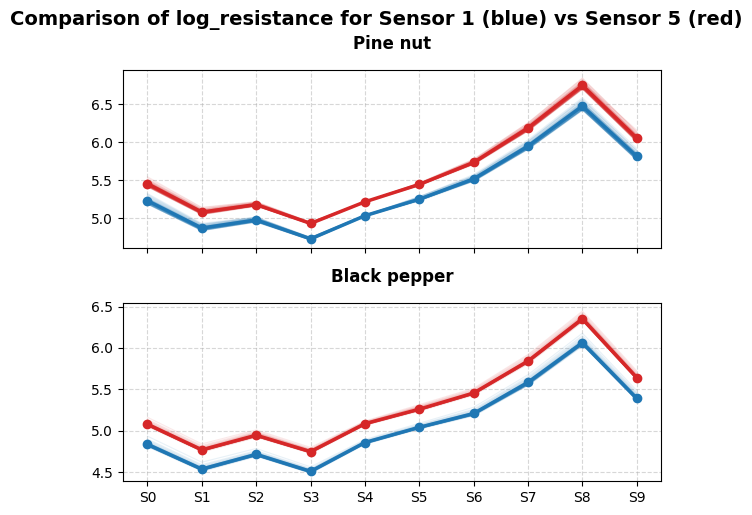

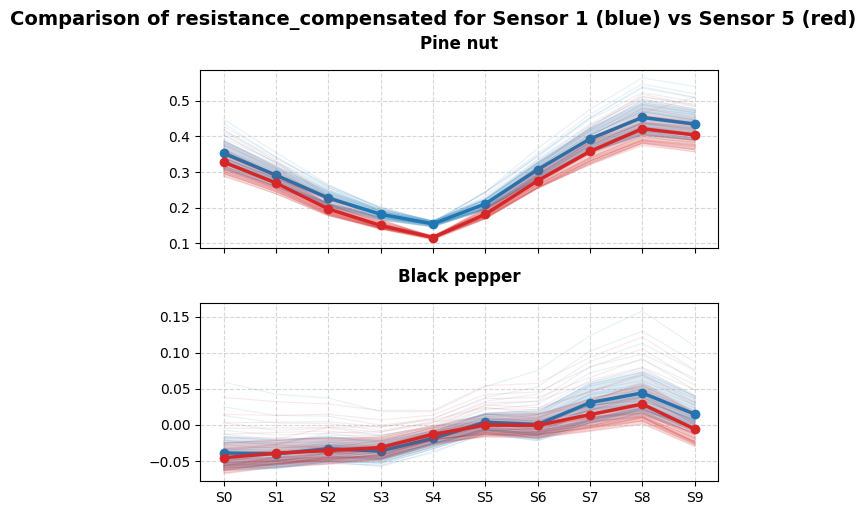

In [6]:
import matplotlib.pyplot as plt
import numpy as np

def plot_fingerprint_comparison(df, target_labels, target_feature):
    
    # Identify column groups
    feat_cols = [col for col in df.columns if col.startswith(target_feature)]
    steps = np.arange(10)

    fig, axes = plt.subplots(len(target_labels), 1, figsize=(6, 2.5*len(target_labels)), sharex=True)

    def draw_group(ax, data, label, color):
        # Filter for the specific gas/label
        mean = np.mean(data, axis=0)
        std = np.std(data, axis=0)

        # 1. Plot individual cycles with very high transparency
        for row in data:
            ax.plot(steps, row, color=color, alpha=0.1, linewidth=0.8)

        # 2. Plot shaded region (variance)
        ax.fill_between(steps, mean - std, mean + std, color=color, alpha=0.15, label='$\pm$1 Std Dev')

        # 3. Plot bold mean line (The "Fingerprint")
        ax.plot(steps, mean, color=color, linewidth=2.5, marker='o', markersize=6, label='Mean Fingerprint')

        ax.set_title(label, fontsize=12, fontweight='bold', pad=15)
        ax.grid(True, linestyle='--', alpha=0.5)
        # ax.legend(loc='upper right')
        ax.set_xticks(steps)
        ax.set_xticklabels([f'S{i}' for i in steps])

    for k, label in enumerate(target_labels):
        # Plot target 
        subset = df[(df['label_merged'] == label) & (df['sensor_index'] == K)]
        data = subset[feat_cols].values
        draw_group(axes[k], data, label, '#1f77b4')
    
        # Plot paired 
        subset = df[(df['label_merged'] == label) & (df['sensor_index'] == PAIR_K)]
        data = subset[feat_cols].values
        draw_group(axes[k], data, label, '#d62728')

    plt.tight_layout()
    plt.suptitle(f'Comparison of {target_feature} for Sensor {K} (blue) vs Sensor {PAIR_K} (red)', fontsize=14, fontweight='bold', y=1.02)
    plt.show()

plot_fingerprint_comparison(feature_matrix, ['Pine nut', 'Black pepper'], 'log_resistance')
plot_fingerprint_comparison(feature_matrix, ['Pine nut', 'Black pepper'], FEATURE_LABEL)


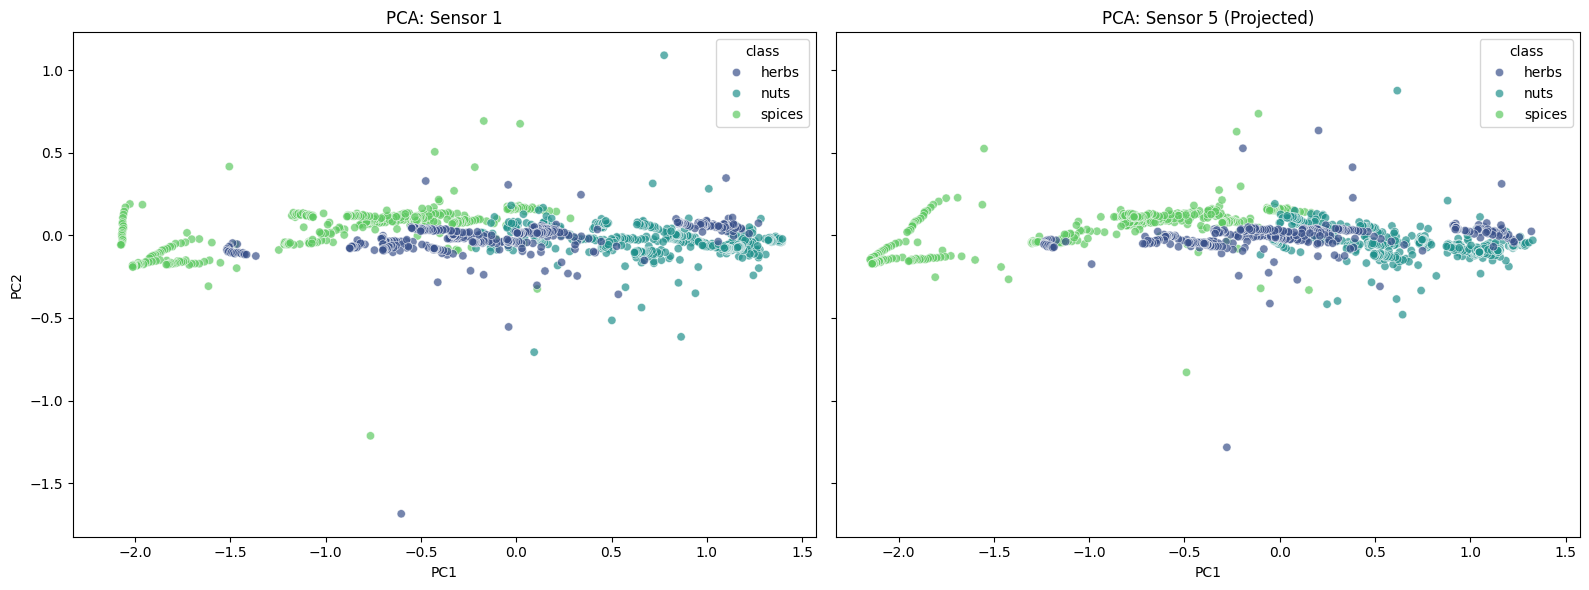

Total Variance Explained: 98.61%


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Separate the pair
df_k = feature_matrix[feature_matrix['sensor_index'] == K].copy()
df_pair = feature_matrix[feature_matrix['sensor_index'] == PAIR_K].copy()

# Feature Selection & Preprocessing
res_cols = [c for c in feature_matrix.columns if FEATURE_LABEL in c]
feature_cols = res_cols

# Standardize and Fit PCA on Sensor K ONLY <= correlation instead of covariance may help scaling?
pca = PCA(n_components=2)

# Fit and transform sensor K
scaler = StandardScaler()
X_k = df_k[feature_cols] #scaler.fit_transform(df_k[feature_cols])
pca_k = pca.fit_transform(X_k)

# Transform sensor K+4 using the SAME scaler and PCA model
X_pair = df_pair[feature_cols] #scaler.transform(df_pair[feature_cols])
pca_pair = pca.transform(X_pair)

# Visualization
# Get a unique list of label_mergeds and sort them alphabetically
# unique_labels = sorted(feature_matrix['label_merged'].unique())
unique_labels = sorted(feature_matrix['class'].unique())

# Create a consistent color palette map
# This assigns a specific color to each label_merged
palette = sns.color_palette("viridis", n_colors=len(unique_labels))
color_map = dict(zip(unique_labels, palette))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Plot Sensor K with explicit hue_order
sns.scatterplot(
    data=df_k,
    x=pca_k[:, 0], y=pca_k[:, 1], 
    hue='class', 
    hue_order=unique_labels, # Ensures consistent color assignment
    palette=color_map, 
    ax=axes[0], 
    alpha=0.7
)
axes[0].set_title(f'PCA: Sensor {K}')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Plot Sensor K+4 with the same hue_order and palette
sns.scatterplot(
    data=df_pair,
    x=pca_pair[:, 0], y=pca_pair[:, 1], 
    hue='class', 
    hue_order=unique_labels, # Critical for consistency
    palette=color_map, 
    ax=axes[1], 
    alpha=0.7
)
axes[1].set_title(f'PCA: Sensor {PAIR_K} (Projected)')
axes[1].set_xlabel('PC1')

plt.tight_layout()
plt.show()

# Print variance explained
print(f"Total Variance Explained: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Feature Selection & Preprocessing
res_cols = [c for c in feature_matrix.columns if FEATURE_LABEL in c]
feature_cols = res_cols

# Scaling (disabled)
scaler = StandardScaler()
X_k_scaled = df_k[feature_cols] #scaler.fit_transform(df_k[feature_cols])
X_pair_scaled = df_pair[feature_cols] #scaler.transform(df_pair[feature_cols])

y_k = df_k['label_merged']
y_pair = df_pair['label_merged']


--- Results for Pair (1, 5) ---
Classification Accuracy on Sensor 5 using Sensor 1 model: 70.26%


C:\Users\blask\AppData\Local\Temp\ipykernel_17448\2290262255.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


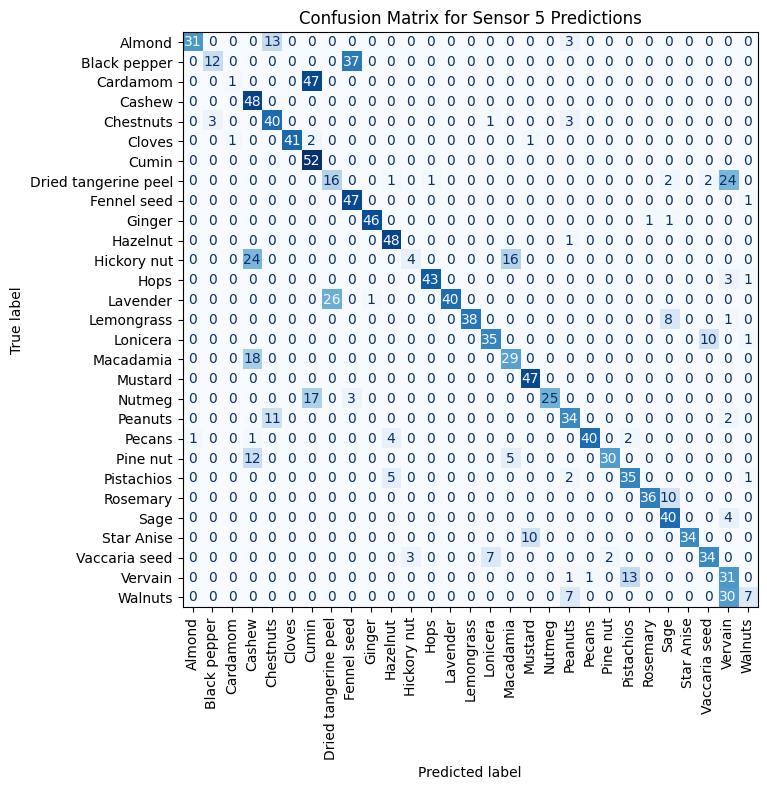

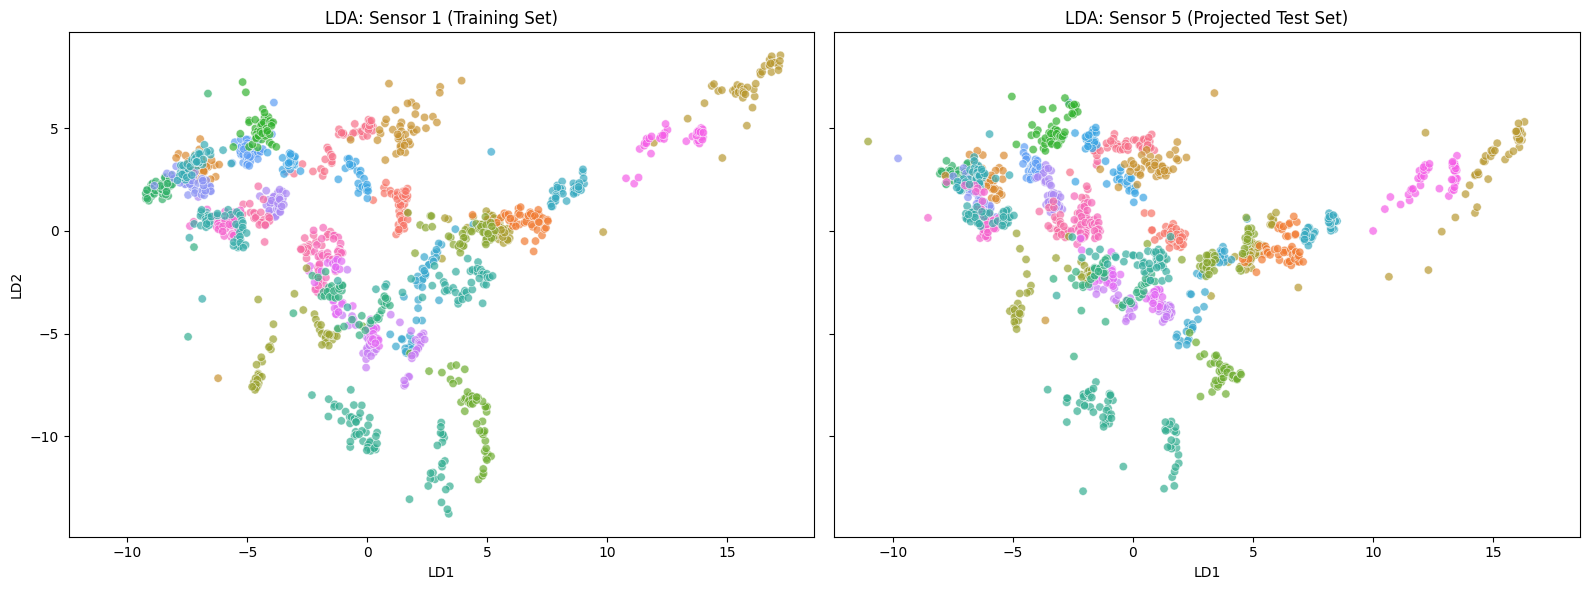

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
# Fit LDA on Sensor K
lda = LinearDiscriminantAnalysis(n_components=2) # We'll project to 2D for the plot
lda_k = lda.fit_transform(X_k_scaled, y_k)

# Project and Score Sensor K+4
# This uses the transformation weights learned from Sensor K
lda_pair = lda.transform(X_pair_scaled)
score_pair = lda.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")

unique_labels = sorted(feature_matrix['label_merged'].unique())
#unique_labels = sorted(feature_matrix['class'].unique())

# Confusion matrix
y_pred_pair = lda.predict(X_pair_scaled)
cm = confusion_matrix(y_pair, y_pred_pair, labels=unique_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_labels)
fig, ax = plt.subplots(figsize=(16, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=90, colorbar=False)
ax.set_title(f'Confusion Matrix for Sensor {PAIR_K} Predictions')
fig.tight_layout()
fig.show()

# Visualization
palette = sns.color_palette("husl", n_colors=len(unique_labels))
color_map = dict(zip(unique_labels, palette))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

# Plot Sensor K
sns.scatterplot(
    x=lda_k[:, 0], y=lda_k[:, 1], 
    hue=y_k, hue_order=unique_labels, palette=color_map,
    ax=axes[0], alpha=0.7
)
# remove legend
axes[0].legend_.remove()
axes[0].set_title(f'LDA: Sensor {K} (Training Set)')
axes[0].set_xlabel('LD1')
axes[0].set_ylabel('LD2')

# Plot Sensor K+4
sns.scatterplot(
    x=lda_pair[:, 0], y=lda_pair[:, 1], 
    hue=y_pair, hue_order=unique_labels, palette=color_map,
    ax=axes[1], alpha=0.7
)
axes[1].legend_.remove()
axes[1].set_title(f'LDA: Sensor {PAIR_K} (Projected Test Set)')
axes[1].set_xlabel('LD1')

plt.tight_layout()
plt.show()



In [10]:
from sklearn.ensemble import RandomForestClassifier
# Fit RandomForest on Sensor K
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_k = rf.fit(X_k_scaled, y_k)

# Project and Score Sensor K+4
# This uses the transformation weights learned from Sensor K
rf_pair = rf.predict(X_pair_scaled)
score_pair = rf.score(X_pair_scaled, y_pair)

print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")

--- Results for Pair (1, 5) ---
Classification Accuracy on Sensor 5 using Sensor 1 model: 57.14%


In [11]:
from sklearn import svm
clf = svm.SVC(kernel='rbf')
clf.fit(X_k_scaled, y_k)
clf_pair = clf.predict(X_pair_scaled)
score_pair = clf.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")


--- Results for Pair (1, 5) ---
Classification Accuracy on Sensor 5 using Sensor 1 model: 54.30%


In [12]:
from sklearn.neural_network import MLPClassifier
clf = MLPClassifier(hidden_layer_sizes=(100,), activation='relu', max_iter=1000)
clf.fit(X_k_scaled, y_k)
score_pair = clf.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")


--- Results for Pair (1, 5) ---
Classification Accuracy on Sensor 5 using Sensor 1 model: 65.52%


c:\Users\blask\Projects\smell\.venv\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [13]:
# KNN with cosine similarity
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5, metric='cosine')
knn.fit(X_k_scaled, y_k)
score_pair = knn.score(X_pair_scaled, y_pair)
print(f"--- Results for Pair ({K}, {PAIR_K}) ---")
print(f"Classification Accuracy on Sensor {PAIR_K} using Sensor {K} model: {score_pair:.2%}")

--- Results for Pair (1, 5) ---
Classification Accuracy on Sensor 5 using Sensor 1 model: 54.88%
